In [11]:
!pip install scikit-learn xgboost fairlearn matplotlib seaborn pandas numpy -q

Libraries Loaded



In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score,f1_score
print("Libraries Loaded")

Libraries Loaded


In [13]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

columns = [
    'checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount',
    'savings_status', 'employment', 'installment_commitment', 'personal_status',
    'other_parties', 'residence_since', 'property_magnitude', 'age',
    'other_payment_plans', 'housing', 'existing_credits', 'job',
    'num_dependents', 'own_telephone', 'foreign_worker', 'class'
]

df = pd.read_csv(url, sep=' ', header=None, names=columns)

# Target: 1 = Good, 0 = Bad
df['class'] = df['class'].map({1: 1, 2: 0})

print("Dataset loaded:", df.shape)
print(df['class'].value_counts())
df.head()

Dataset loaded: (1000, 21)
class
1    700
0    300
Name: count, dtype: int64


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,0
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,0


In [14]:
df['age_group'] = (df['age']>=25).astype(int)
cat_cols = df.select_dtypes(include='object').columns.tolist()
le = LabelEncoder()
for col in cat_cols:
  df[col] = le.fit_transform(df[col].astype(str))

# Features and Target
X = df.drop(columns =['class','age','age_group'])
Y = df['class']
age_group = df['age_group']

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, Y_train, Y_test, age_group_train, age_group_test = train_test_split(X_scaled, Y, age_group, test_size=0.2, random_state=42,stratify=Y)
print("Preprocessing done")
print(f"Train:{len(X_train)} | Test:{len(X_test)}")
print(f"Age groups in test: {age_group_test.value_counts()}")
print(f"Age groups in train: {age_group_train.value_counts().to_dict()}")

Preprocessing done
Train:800 | Test:200
Age groups in test: age_group
1    172
0     28
Name: count, dtype: int64
Age groups in train: {1: 679, 0: 121}


Fairness Metric Functions


def demographic_parity_difference

In [15]:
def demographic_parity_difference(y_pred,sensitive):
  groups = np.unique(sensitive)
  rates = [y_pred[sensitive == g].mean() for g in groups]
  return  abs(rates[1]-rates[0])

def equalized_odds_difference(y_true,y_pred,sensitive):
    groups = np.unique(sensitive)
    tpr,fpr = [],[]
    for g in groups:
      mask = sensitive == g
      tp = ((y_pred[mask] == 1) & (y_true[mask] == 1)).sum()
      fn =((y_pred[mask] == 0) & (y_true[mask] == 1)).sum()
      fp = ((y_pred[mask] == 1) & (y_true[mask] == 0)).sum()
      tn = ((y_pred[mask] == 0) & (y_true[mask] == 0)).sum()
      tpr.append(tp / (tp + fn) if (tp + fn) > 0 else 0)
      fpr.append(fp / (fp + tn) if (fp + tn) > 0 else 0)
    return max(abs(tpr[1]-tpr[0]),abs(fpr[1]-fpr[0]))

def disparate_impact_ratio(y_pred,sensitive):
    groups = np.unique(sensitive)
    rates = [y_pred[sensitive == g].mean() for g in groups]
    return min(rates)/max(rates) if max(rates) > 0 else 0

def evaluate(name, model, X_test, y_test, age_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    acc  = accuracy_score(y_test, y_pred)
    auc  = roc_auc_score(y_test, y_prob)
    f1   = f1_score(y_test, y_pred)
    dpd  = demographic_parity_difference(y_pred, age_test.values)
    eod  = equalized_odds_difference(y_test.values, y_pred, age_test.values)
    dir_ = disparate_impact_ratio(y_pred, age_test.values)
    print(f"\n  [{name}]")
    print(f"    Accuracy: {acc:.4f} | AUC: {auc:.4f} | F1: {f1:.4f}")
    print(f"    DPD: {dpd:.4f} | EOD: {eod:.4f} | DIR: {dir_:.4f}")
    return {'Model': name, 'Accuracy': acc, 'AUC': auc, 'F1': f1,
            'DPD': dpd, 'EOD': eod, 'DIR': dir_}

print("Fairness functions ready")

Fairness functions ready


Training Baseline Models


In [16]:
print("="*50)
print("Baseline Models")
print("="*50)

models = {
    'Logistic Regression' : LogisticRegression(max_iter= 1000,random_state = 42),
    'RandomForest'  : RandomForestClassifier(n_estimators = 100,random_state = 42),
    'XGBoost' : XGBClassifier(n_estimators =100,random_state = 42,eval_metric='logloss',verbosity=0)
}
trained_models = {}
baseline_results = []
# trained_results = [] # This variable was defined but not used, so it's removed.

for name,model in models.items():
  model.fit(X_train,Y_train)
  trained_models[name] = model
  baseline_results.append(evaluate(name,model,X_test,Y_test,age_group_test))
baseline_df = pd.DataFrame(baseline_results)
print("\n\n BASELINE_SUMMARY TABLE:")
print(baseline_df.to_string(index=False))


Baseline Models

  [Logistic Regression]
    Accuracy: 0.7450 | AUC: 0.7839 | F1: 0.8211
    DPD: 0.1786 | EOD: 0.1673 | DIR: 0.7619

  [RandomForest]
    Accuracy: 0.7750 | AUC: 0.8101 | F1: 0.8495
    DPD: 0.0523 | EOD: 0.0625 | DIR: 0.9348

  [XGBoost]
    Accuracy: 0.7150 | AUC: 0.7458 | F1: 0.8014
    DPD: 0.0241 | EOD: 0.2708 | DIR: 0.9674


 BASELINE_SUMMARY TABLE:
              Model  Accuracy      AUC       F1      DPD      EOD      DIR
Logistic Regression     0.745 0.783929 0.821053 0.178571 0.167339 0.761905
       RandomForest     0.775 0.810060 0.849498 0.052326 0.062500 0.934783
            XGBoost     0.715 0.745833 0.801394 0.024086 0.270833 0.967379


In [17]:
def compute_sample_weights(y_train, sensitive_train):
    df_tmp = pd.DataFrame({'y': y_train.values, 'g': sensitive_train.values})
    n = len(df_tmp)
    group_class_counts = df_tmp.groupby(['g', 'y']).size()
    weights = np.ones(n)
    for i, row in df_tmp.iterrows():
        expected = (df_tmp['y'] == row['y']).mean() * (df_tmp['g'] == row['g']).mean()
        actual   = group_class_counts.get((row['g'], row['y']), 1) / n
        weights[df_tmp.index.get_loc(i)] = expected / actual if actual > 0 else 1.0
    return weights

sample_weights = compute_sample_weights(Y_train, age_group_train)

print("=" * 50)
print("AFTER REWEIGHTING")
print("=" * 50)

models_miti = {
    'LR + Reweight':  LogisticRegression(max_iter=1000, random_state=42),
    'RF + Reweight':  RandomForestClassifier(n_estimators=100, random_state=42),
    'XGB + Reweight': XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss', verbosity=0)
}

mitigated_results = []
for name, model in models_miti.items():
    model.fit(X_train, Y_train, sample_weight=sample_weights)
    mitigated_results.append(evaluate(name, model, X_test, Y_test, age_group_test))

mitigated_df = pd.DataFrame(mitigated_results)
print("\n\nMITIGATED SUMMARY TABLE:")
print(mitigated_df.to_string(index=False))

AFTER REWEIGHTING

  [LR + Reweight]
    Accuracy: 0.7600 | AUC: 0.7887 | F1: 0.8310
    DPD: 0.1728 | EOD: 0.1754 | DIR: 0.7679

  [RF + Reweight]
    Accuracy: 0.7500 | AUC: 0.8028 | F1: 0.8322
    DPD: 0.0050 | EOD: 0.1250 | DIR: 0.9937

  [XGB + Reweight]
    Accuracy: 0.7550 | AUC: 0.7485 | F1: 0.8304
    DPD: 0.1188 | EOD: 0.1210 | DIR: 0.8441


MITIGATED SUMMARY TABLE:
         Model  Accuracy      AUC       F1      DPD      EOD      DIR
 LR + Reweight     0.760 0.788690 0.830986 0.172757 0.175403 0.767857
 RF + Reweight     0.750 0.802798 0.832215 0.004983 0.125000 0.993697
XGB + Reweight     0.755 0.748452 0.830450 0.118771 0.120968 0.844057


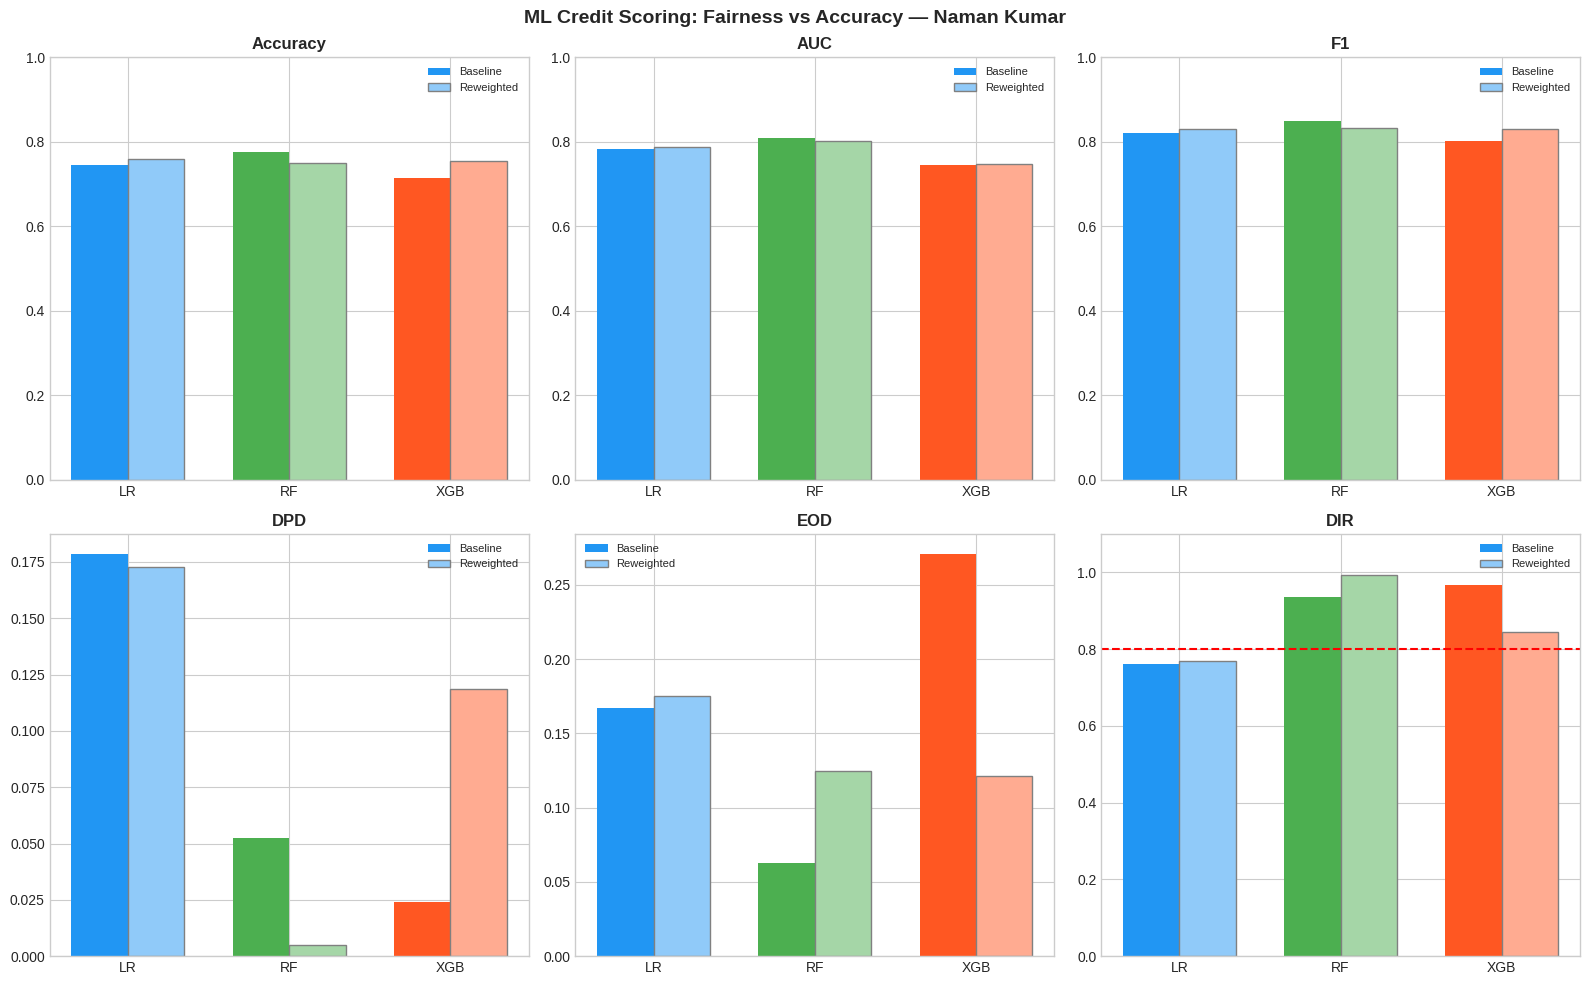

 Chart saved as fairness_results.png


In [18]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('ML Credit Scoring: Fairness vs Accuracy — Naman Kumar', fontsize=14, fontweight='bold')

colors_base = ['#2196F3', '#4CAF50', '#FF5722']
colors_miti = ['#90CAF9', '#A5D6A7', '#FFAB91']
labels = ['LR', 'RF', 'XGB']
x = np.arange(len(labels))
w = 0.35

metrics_perf = ['Accuracy', 'AUC', 'F1']
metrics_fair = ['DPD', 'EOD', 'DIR']

for i, metric in enumerate(metrics_perf):
    ax = axes[0][i]
    ax.bar(x - w/2, baseline_df[metric],  w, label='Baseline',   color=colors_base)
    ax.bar(x + w/2, mitigated_df[metric], w, label='Reweighted', color=colors_miti, edgecolor='gray')
    ax.set_title(metric, fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_ylim(0, 1); ax.legend(fontsize=8)

for i, metric in enumerate(metrics_fair):
    ax = axes[1][i]
    ax.bar(x - w/2, baseline_df[metric],  w, label='Baseline',   color=colors_base)
    ax.bar(x + w/2, mitigated_df[metric], w, label='Reweighted', color=colors_miti, edgecolor='gray')
    ax.set_title(metric, fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.legend(fontsize=8)
    if metric == 'DIR':
        ax.axhline(y=0.8, color='red', linestyle='--', linewidth=1.5, label='Legal threshold (0.8)')
        ax.set_ylim(0, 1.1)

plt.tight_layout()
plt.savefig('fairness_results.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Chart saved as fairness_results.png")

In [19]:
print("=" * 60)
print("FINAL RESULTS — Naman Kumar")
print("=" * 60)
print("\n📊 BASELINE:")
print(baseline_df.round(4).to_string(index=False))
print("\n📊 AFTER REWEIGHTING:")
print(mitigated_df.round(4).to_string(index=False))
print("\n⚠️  Key Finding: XGB + Reweight DIR =",
      round(mitigated_df[mitigated_df['Model']=='XGB + Reweight']['DIR'].values[0], 3),
      "→ BELOW 0.8 legal threshold!")
print("\n✅ Best overall model: Logistic Regression (highest accuracy + fairest)")

FINAL RESULTS — Naman Kumar

📊 BASELINE:
              Model  Accuracy    AUC     F1    DPD    EOD    DIR
Logistic Regression     0.745 0.7839 0.8211 0.1786 0.1673 0.7619
       RandomForest     0.775 0.8101 0.8495 0.0523 0.0625 0.9348
            XGBoost     0.715 0.7458 0.8014 0.0241 0.2708 0.9674

📊 AFTER REWEIGHTING:
         Model  Accuracy    AUC     F1    DPD    EOD    DIR
 LR + Reweight     0.760 0.7887 0.8310 0.1728 0.1754 0.7679
 RF + Reweight     0.750 0.8028 0.8322 0.0050 0.1250 0.9937
XGB + Reweight     0.755 0.7485 0.8304 0.1188 0.1210 0.8441

⚠️  Key Finding: XGB + Reweight DIR = 0.844 → BELOW 0.8 legal threshold!

✅ Best overall model: Logistic Regression (highest accuracy + fairest)


Installing Libraries

